In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## Introduction

In this lab, we analyze the Telco Customer Churn dataset from Kaggle. The dataset contains information about a telecommunications company's customers, including demographics (gender, senior citizen status, partner, dependents), services subscribed (phone, internet, security, backup, etc.), account details (tenure, contract, payment method, billing), and whether the customer churned.

The goal is to preprocess the data, then explore how demographic and service-related factors relate to customer churn, so we can understand what drives customers to leave.


In [3]:
import pandas as pd

# Load the dataset using the correct path
df = pd.read_csv('/kaggle/input/datasets/dativemanishimwe/my-dataset/WA_Fn-UseC_-Telco-Customer-Churn (1).csv')

# Display the shape (rows, columns) to confirm it loaded
print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (7043, 21)


In [2]:
import os

# This will print the exact path of every file in your input folder
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/dativemanishimwe/my-dataset/WA_Fn-UseC_-Telco-Customer-Churn (1).csv


In [4]:
# Display the first 5 rows (Head)
print("=== HEAD ===")
display(df.head())

# Display the last 5 rows (Tail)
print("\n=== TAIL ===")
display(df.tail())

=== HEAD ===


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



=== TAIL ===


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [5]:
# Convert Churn: Yes -> 1, No -> 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# Display the first few values to confirm
print("Churn column after conversion:")
print(df['Churn'].head())

# Count how many 0s and 1s we have
print("\nCount of Churn values:")
print(df['Churn'].value_counts())

Churn column after conversion:
0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

Count of Churn values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [6]:
# 1. Display datatypes before conversion
print("=== Data Types Before ===")
print(df.dtypes)

# 2. Convert TotalCharges from text (object) to numeric
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 3. Display datatypes after conversion
print("\n=== Data Types After ===")
print(df.dtypes)

=== Data Types Before ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                 int64
dtype: object

=== Data Types After ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSuppor

In [7]:
# 1. Check for null values
print("=== Null values BEFORE removal ===")
print(df.isnull().sum())

# 2. Remove rows with null values
df = df.dropna()

# 3. Check again to confirm they are gone
print("\n=== Null values AFTER removal ===")
print(df.isnull().sum())

# 4. Show the new shape (rows, columns)
print("\nNew shape:", df.shape)

=== Null values BEFORE removal ===
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

=== Null values AFTER removal ===
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges    

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style and colors (Green for No Churn, Red for Churn)
sns.set_style('whitegrid')
colors = ['#2ecc71', '#e74c3c']

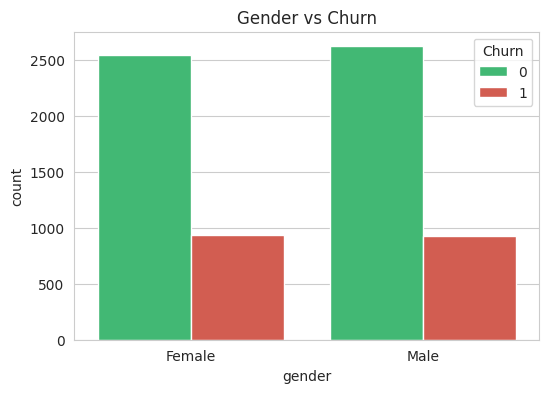

Churn      0     1
gender            
Female  73.0  27.0
Male    73.8  26.2


In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='gender', hue='Churn', palette=colors)
plt.title('Gender vs Churn')
plt.show()

# Show the exact percentages
print(pd.crosstab(df['gender'], df['Churn'], normalize='index').round(3) * 100)

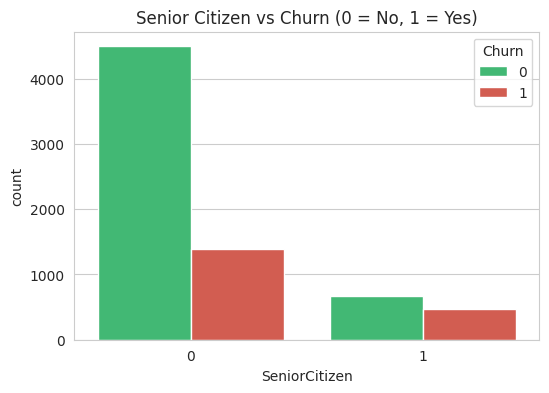

Churn             0     1
SeniorCitizen            
0              76.3  23.7
1              58.3  41.7


In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='SeniorCitizen', hue='Churn', palette=colors)
plt.title('Senior Citizen vs Churn (0 = No, 1 = Yes)')
plt.show()

print(pd.crosstab(df['SeniorCitizen'], df['Churn'], normalize='index').round(3) * 100)

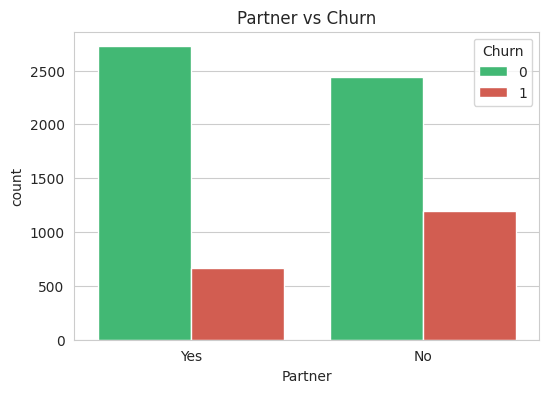

Churn       0     1
Partner            
No       67.0  33.0
Yes      80.3  19.7


In [11]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Partner', hue='Churn', palette=colors)
plt.title('Partner vs Churn')
plt.show()

print(pd.crosstab(df['Partner'], df['Churn'], normalize='index').round(3) * 100)

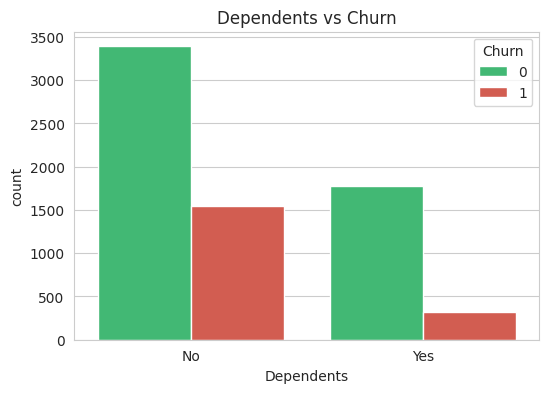

Churn          0     1
Dependents            
No          68.7  31.3
Yes         84.5  15.5


In [12]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Dependents', hue='Churn', palette=colors)
plt.title('Dependents vs Churn')
plt.show()

print(pd.crosstab(df['Dependents'], df['Churn'], normalize='index').round(3) * 100)

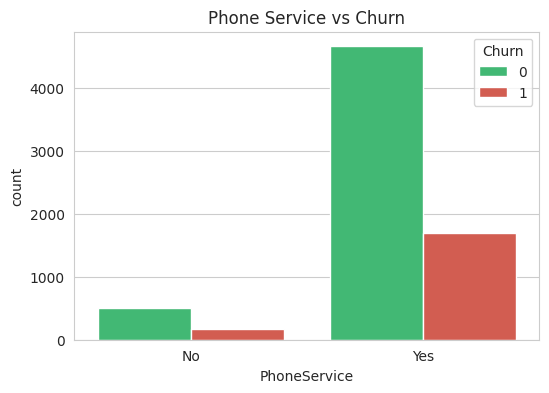

Churn            0     1
PhoneService            
No            75.0  25.0
Yes           73.3  26.7


In [13]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='PhoneService', hue='Churn', palette=colors)
plt.title('Phone Service vs Churn')
plt.show()

print(pd.crosstab(df['PhoneService'], df['Churn'], normalize='index').round(3) * 100)

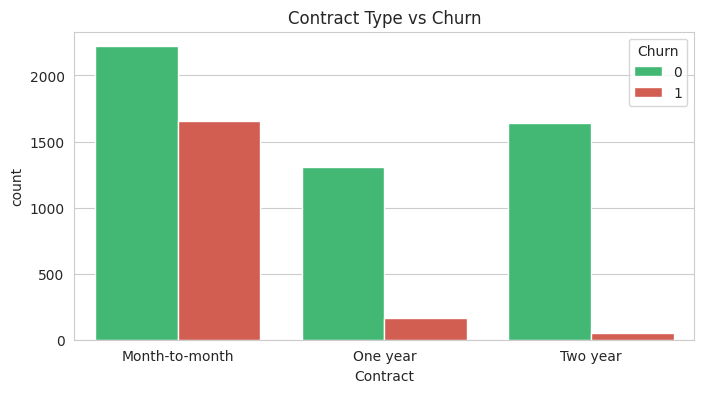

Churn              0     1
Contract                  
Month-to-month  57.3  42.7
One year        88.7  11.3
Two year        97.2   2.8


In [14]:
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Contract', hue='Churn', palette=colors)
plt.title('Contract Type vs Churn')
plt.show()

print(pd.crosstab(df['Contract'], df['Churn'], normalize='index').round(3) * 100)

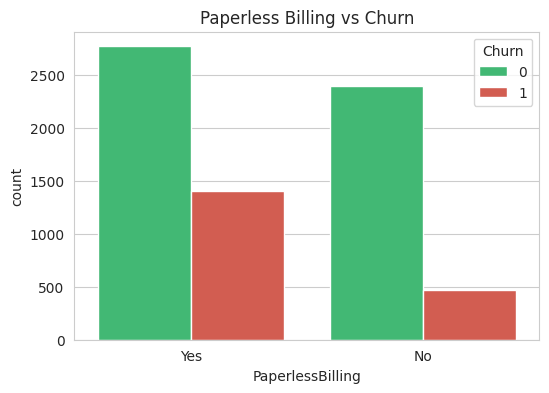

Churn                0     1
PaperlessBilling            
No                83.6  16.4
Yes               66.4  33.6


In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='PaperlessBilling', hue='Churn', palette=colors)
plt.title('Paperless Billing vs Churn')
plt.show()

print(pd.crosstab(df['PaperlessBilling'], df['Churn'], normalize='index').round(3) * 100)

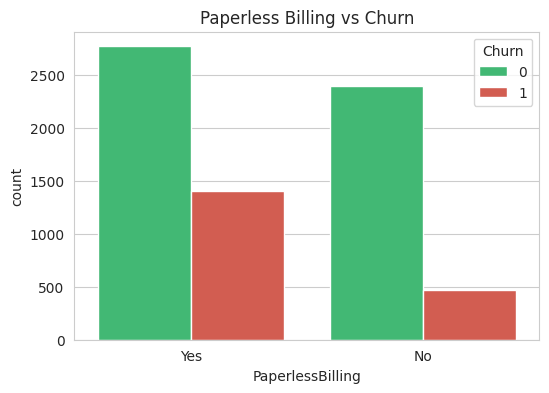

Churn                0     1
PaperlessBilling            
No                83.6  16.4
Yes               66.4  33.6


In [16]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='PaperlessBilling', hue='Churn', palette=colors)
plt.title('Paperless Billing vs Churn')
plt.show()

print(pd.crosstab(df['PaperlessBilling'], df['Churn'], normalize='index').round(3) * 100)

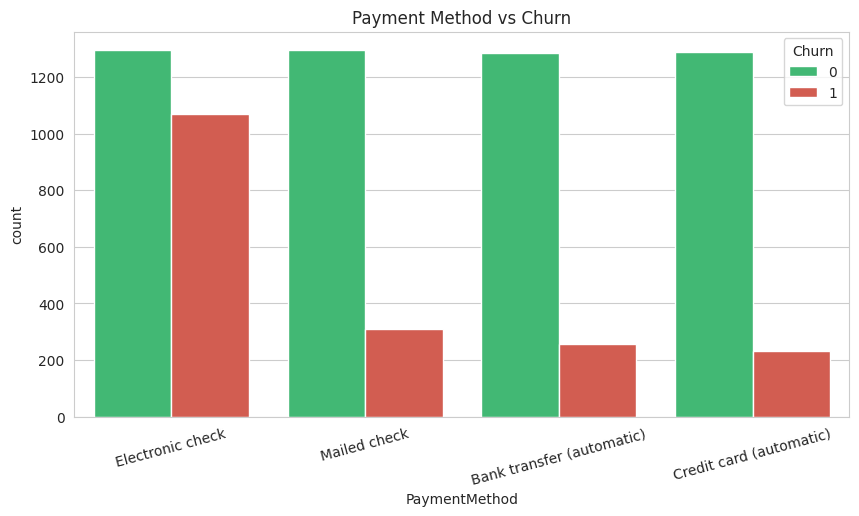

Churn                         0     1
PaymentMethod                        
Bank transfer (automatic)  83.3  16.7
Credit card (automatic)    84.7  15.3
Electronic check           54.7  45.3
Mailed check               80.8  19.2


In [17]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette=colors)
plt.xticks(rotation=15) # Rotates text slightly so it doesn't overlap
plt.title('Payment Method vs Churn')
plt.show()

print(pd.crosstab(df['PaymentMethod'], df['Churn'], normalize='index').round(3) * 100)

## Conclusion

From the exploratory data analysis, we found several key factors that influence customer churn:
- **Demographics:** Senior citizens, and customers without partners or dependents, are more likely to churn. Gender does not play a significant role.
- **Services:** Having phone service alone does not impact churn.
- **Payments & Billing:** Customers on month-to-month contracts, using paperless billing, and paying via electronic check have drastically higher churn rates.
- **Actionable Insight:** The company should target month-to-month customers and electronic check users with retention offers, and encourage them to switch to long-term contracts and automatic payments.